| **Inicio**         | **atrás 5**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./4_5_Integrales_multiples.ipynb) |

# 1. El mapa mental que debes tener

Todo este capítulo se puede organizar así:

```text
                    CÁLCULO VECTORIAL
                           │
             ┌─────────────┴─────────────┐
             │                           │
       CAMPOS ESCALARES            CAMPOS VECTORIALES
             │                           │
         gradiente              ┌────────┼────────┐
             │                  │        │        │
             │                div(F)   curl(F)    │
             │                  │        │        │
             └──────────────────┴────────┴────────┘
                                     │
                              INTEGRALES
                                     │
                     ┌───────────────┼───────────────┐
                     │               │               │
                línea            superficie        volumen
                     │               │               │
                     └───────────────┼───────────────┘
                                     │
                              TEOREMAS
                       ┌─────────────┼─────────────┐
                       │             │             │
                     Green         Stokes         Gauss
```

Y existe una idea todavía más profunda:

$$
\boxed{
\text{derivadas locales}
\quad\longleftrightarrow\quad
\text{integrales globales}
}
$$

Los teoremas de Green, Stokes y Gauss son diferentes manifestaciones de esa idea.

# 2. Campos escalares y vectoriales

Antes del gradiente, divergencia y curl necesitamos entender qué es un campo.

## Campo escalar

Un campo escalar asigna un número a cada punto:

$$
f:\mathbb R^3\rightarrow\mathbb R.
$$

Por ejemplo:

$$
T(x,y,z)
$$

puede representar temperatura.

Otros ejemplos:

* presión,
* densidad,
* concentración,
* potencial eléctrico,
* energía.

Una temperatura podría ser:

$$
T(x,y,z)
=
20+x^2+y^2-0.5z.
$$

Cada punto tiene una temperatura.

# 3. Campo vectorial

Un campo vectorial asigna un vector a cada punto:

$$
\boxed{
\mathbf F(x,y,z)
=
(F_1,F_2,F_3)
}
$$

Por ejemplo:

$$
\mathbf F(x,y,z)
=
(-y,x,0).
$$

En cada punto del espacio tenemos una flecha.

Esto aparece constantemente en física:

### Velocidad de un fluido

$$
\mathbf v(x,y,z).
$$

### Campo eléctrico

$$
\mathbf E(x,y,z).
$$

### Campo magnético

$$
\mathbf B(x,y,z).
$$

### Fuerza

$$
\mathbf F(x,y,z).
$$

# 4. Primer gráfico: campo vectorial

Consideremos

$$
\mathbf F(x,y)=(-y,x).
$$

Este campo genera rotación alrededor del origen.

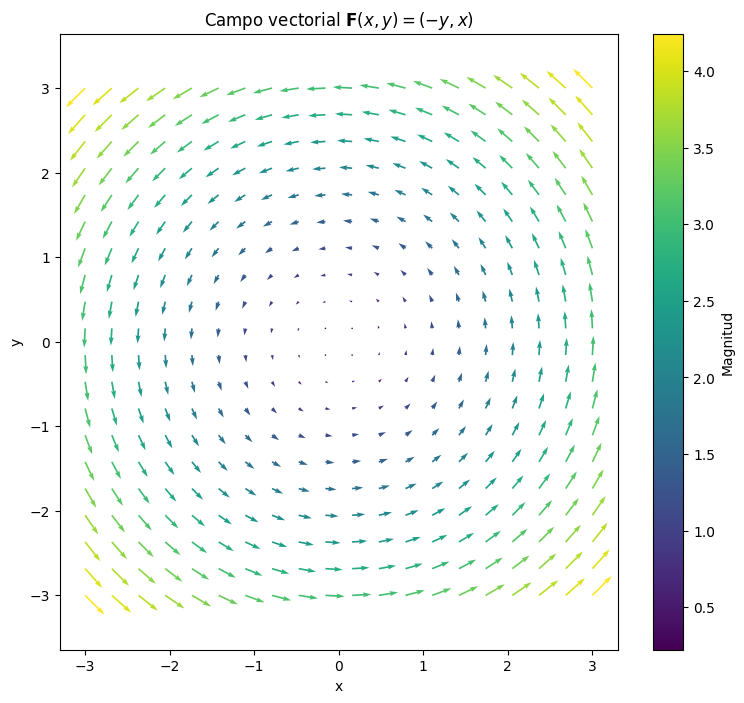

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 20)
y = np.linspace(-3, 3, 20)

X, Y = np.meshgrid(x, y)

U = -Y
V = X

magnitude = np.sqrt(U**2 + V**2)

plt.figure(figsize=(9, 8))

plt.quiver(
    X, Y,
    U, V,
    magnitude,
    cmap="viridis"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Campo vectorial $\mathbf{F}(x,y)=(-y,x)$")

plt.axis("equal")
plt.colorbar(label="Magnitud")

plt.show()

Observa la geometría:

$$
\mathbf F=(-y,x)
$$

es tangencial a círculos centrados en el origen.

Eso ya nos está dando una pista de lo que será el **curl**.

# 5. Gradiente

Supongamos que tenemos un campo escalar:

$$
f(x,y,z).
$$

Su gradiente es:

$$
\boxed{
\nabla f
=
\left(
\frac{\partial f}{\partial x},
\frac{\partial f}{\partial y},
\frac{\partial f}{\partial z}
\right)
}
$$

En 2D:

$$
\boxed{
\nabla f
=
\left(
f_x,f_y
\right)
}
$$

# 6. ¿Qué significa físicamente el gradiente?

El gradiente apunta hacia la dirección donde $(f)$ aumenta más rápidamente.

Además:

$$
\boxed{
|\nabla f|
=
\text{máxima tasa de crecimiento de }f
}
$$

Esta interpretación es fundamental.

# 7. Ejemplo difícil de gradiente

Consideremos:

$$
f(x,y,z)
=
x^2y\,e^{-z}
+
\sin(xy).
$$

Entonces:

$$
\frac{\partial f}{\partial x}
=
2xye^{-z}
+
y\cos(xy)
$$

$$
\frac{\partial f}{\partial y}
=
x^2e^{-z}
+
x\cos(xy)
$$

$$
\frac{\partial f}{\partial z}
=
-x^2ye^{-z}.
$$

Por tanto:

$$
\boxed{
\nabla f=
\left(
2xye^{-z}+y\cos(xy),
x^2e^{-z}+x\cos(xy),
-x^2ye^{-z}
\right)
}
$$

# 8. Gradiente y machine learning

Aquí aparece una conexión fundamental.

En ML normalmente tienes una función de pérdida:

$$
L(\theta_1,\theta_2,\ldots,\theta_n).
$$

Su gradiente es:

$$
\boxed{
\nabla_\theta L
}
$$

y el entrenamiento utiliza:

$$
\theta_{\text{nuevo}}
=
\theta
-
\eta\nabla_\theta L.
$$

Es decir:

$$
\boxed{
\text{gradient descent}
=
\text{movimiento en dirección opuesta al gradiente}
}
$$

Por eso entender el gradiente desde cálculo vectorial es fundamental para ML.

# 9. Visualización del gradiente en Python

Tomemos:

$$
f(x,y)
=
x^2+2y^2.
$$

Entonces:

$$
\nabla f=(2x,4y).
$$

Las curvas de nivel son elipses.

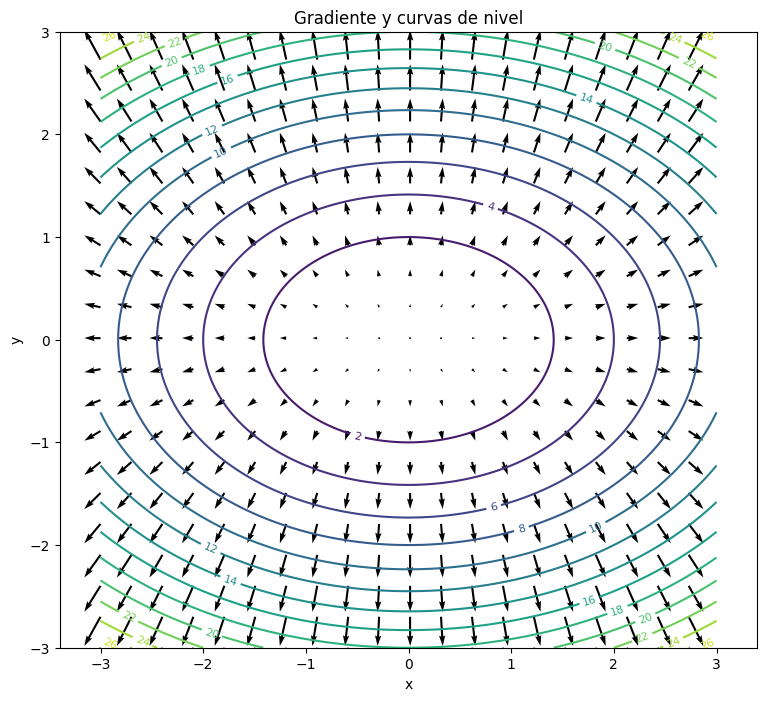

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 200)
y = np.linspace(-3, 3, 200)

X, Y = np.meshgrid(x, y)

Z = X**2 + 2*Y**2

Fx = 2*X
Fy = 4*Y

plt.figure(figsize=(9, 8))

levels = plt.contour(
    X, Y, Z,
    levels=15
)

plt.clabel(levels, inline=True, fontsize=8)

plt.quiver(
    X[::10, ::10],
    Y[::10, ::10],
    Fx[::10, ::10],
    Fy[::10, ::10]
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Gradiente y curvas de nivel")

plt.axis("equal")
plt.show()

La observación importante:

$$
\boxed{
\nabla f\perp\text{ curvas de nivel}
}
$$

# 10. Derivada direccional

El gradiente también permite calcular cuánto cambia una función en una dirección determinada.

Sea un vector unitario:

$$
\mathbf u.
$$

La derivada direccional es:

$$
\boxed{
D_{\mathbf u}f
=
\nabla f\cdot\mathbf u
}
$$

Esto es extremadamente importante.

Si:

$$
\nabla f=(3,4)
$$

y

$$
\mathbf u=
\left(
\frac35,\frac45
\right),
$$

entonces:

$$
D_{\mathbf u}f
=
3\frac35+4\frac45
=
5.
$$

La máxima derivada direccional es:

$$
\boxed{|\nabla f|}
$$

y ocurre en la dirección:

$$
\boxed{
\frac{\nabla f}{|\nabla f|}
}
$$

# 11. Divergencia

Ahora pasamos de un campo escalar a un campo vectorial.

Sea:

$$
\mathbf F=(P,Q,R).
$$

La divergencia es:

$$
\boxed{
\nabla\cdot\mathbf F
=
\frac{\partial P}{\partial x}
+
\frac{\partial Q}{\partial y}
+
\frac{\partial R}{\partial z}
}
$$

# 12. Intuición física de la divergencia

Piensa en un fluido.

Si:

$$
\nabla\cdot\mathbf F>0,
$$

tenemos una especie de **fuente**.

El campo sale del punto.

Si:

$$
\nabla\cdot\mathbf F<0,
$$

tenemos un **sumidero**.

El campo entra al punto.

Si:

$$
\nabla\cdot\mathbf F=0,
$$

localmente no hay creación neta de flujo.

# 13. Ejemplo difícil de divergencia

Consideremos:

$$
\mathbf F(x,y,z)
=
\left(
x^2y,\,
yz^2,\,
ze^{-x}
\right).
$$

Entonces:

$$
\nabla\cdot\mathbf F
=
\frac{\partial}{\partial x}(x^2y)
+
\frac{\partial}{\partial y}(yz^2)
+
\frac{\partial}{\partial z}(ze^{-x}).
$$

Tenemos:

$$
\frac{\partial}{\partial x}(x^2y)=2xy
$$

$$
\frac{\partial}{\partial y}(yz^2)=z^2
$$

$$
\frac{\partial}{\partial z}(ze^{-x})=e^{-x}.
$$

Por tanto:

$$
\boxed{
\nabla\cdot\mathbf F
=
2xy+z^2+e^{-x}
}
$$

# 14. Visualizar divergencia

Podemos graficar un campo 2D y colorear la magnitud de su divergencia.

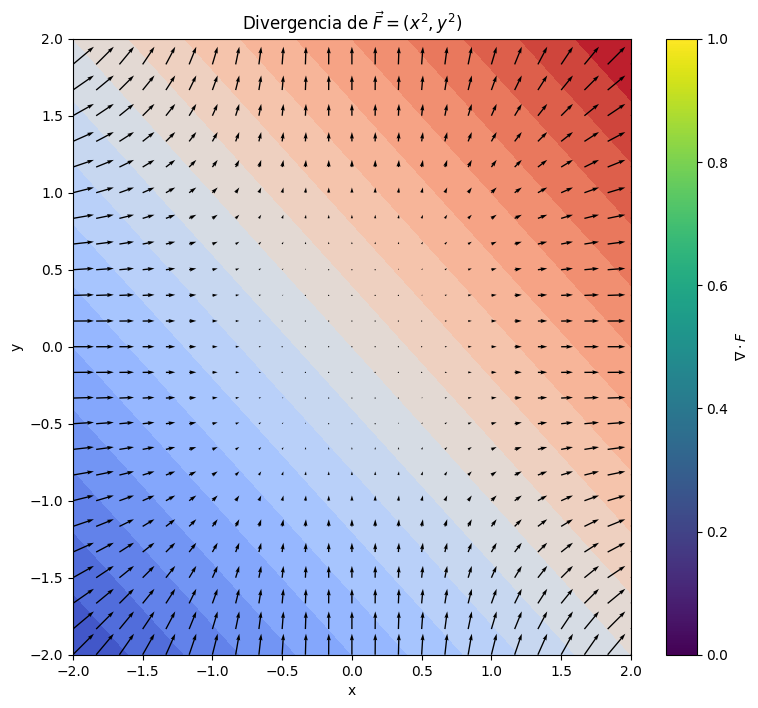

In [4]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 2, 25)
y = np.linspace(-2, 2, 25)

X, Y = np.meshgrid(x, y)

# Campo vectorial
U = X**2
V = Y**2

# Divergencia:
# dU/dx + dV/dy
# = 2x + 2y
divF = 2*X + 2*Y

plt.figure(figsize=(9, 8))

plt.contourf(
    X,
    Y,
    divF,
    levels=20,
    cmap="coolwarm"
)

plt.quiver(
    X,
    Y,
    U,
    V,
    color="black"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(r"Divergencia de $\vec{F}=(x^2,y^2)$")

plt.colorbar(label=r"$\nabla\cdot F$")

plt.show()

# 15. Curl

El curl mide la tendencia local de un campo vectorial a rotar.

Para:

$$
\mathbf F=(P,Q,R)
$$

tenemos:

$$
\boxed{
\nabla\times\mathbf F
=
\begin{pmatrix}
R_y-Q_z\\
P_z-R_x\\
Q_x-P_y
\end{pmatrix}
}
$$

# 16. Intuición física del curl

Imagina colocar una pequeña hélice en un fluido.

Si la hélice empieza a girar, existe curl.

Por eso:

$$
\boxed{
\text{curl}
\approx
\text{rotación local}
}
$$

No significa simplemente que las flechas del dibujo "se vean curvas"; mide una propiedad diferencial precisa del campo.

# 17. Ejemplo difícil de curl

Consideremos:

$$
\mathbf F
=
\left(
yz,\,
xz,\,
xy
\right).
$$

Entonces:

$$
\nabla\times\mathbf F
=
\begin{pmatrix}
\partial_y(xy)-\partial_z(xz)\\
\partial_z(yz)-\partial_x(xy)\\
\partial_x(xz)-\partial_y(yz)
\end{pmatrix}.
$$

Calculamos:

$$
\partial_y(xy)=x
$$

$$
\partial_z(xz)=x
$$

por lo tanto:

$$
x-x=0.
$$

Los otros componentes también son cero.

Así:

$$
\boxed{
\nabla\times\mathbf F=0
}
$$

Este es un ejemplo interesante porque el campo puede ser no trivial y, sin embargo, tener curl cero.

# 18. Ejemplo de campo con rotación

Tomemos:

$$
\mathbf F=(-y,x,0).
$$

Entonces:

$$
\nabla\times\mathbf F
=
(0,0,2).
$$

Por tanto:

$$
\boxed{
\nabla\times\mathbf F=2\mathbf k
}
$$

Hay rotación alrededor del eje $(z)$.

# 19. Gráfico del curl

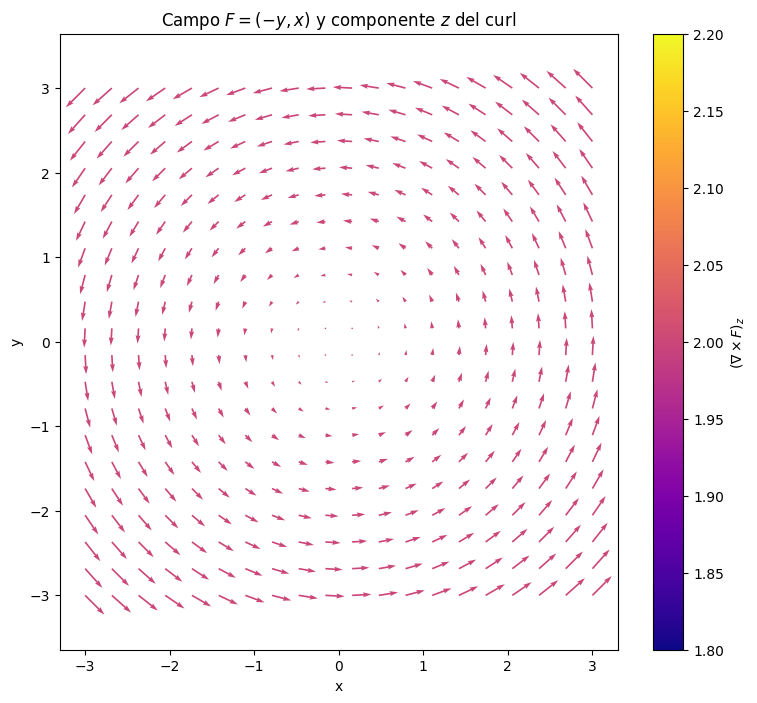

In [6]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 20)
y = np.linspace(-3, 3, 20)

X, Y = np.meshgrid(x, y)

U = -Y
V = X

curl_z = 2 * np.ones_like(X)

plt.figure(figsize=(9, 8))

plt.quiver(
    X, Y,
    U, V,
    curl_z,
    cmap="plasma"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(r"Campo $F=(-y,x)$ y componente $z$ del curl")

plt.axis("equal")

plt.colorbar(label=r"$(\nabla\times F)_z$")

plt.show()

# 20. Una distinción MUY importante

No confundas:

$$
\nabla f
$$

con

$$
\nabla\cdot\mathbf F
$$

ni con

$$
\nabla\times\mathbf F.
$$

Piensa:

| Operación   | Entrada | Salida  | Interpretación                  |
| ----------- | ------- | ------- | ------------------------------- |
| Gradiente   | escalar | vector  | dirección de máximo crecimiento |
| Divergencia | vector  | escalar | expansión/compresión            |
| Curl        | vector  | vector  | rotación local                  |

Es decir:

$$
\boxed{
f
\overset{\nabla}{\longrightarrow}
\nabla f
}
$$

$$
\boxed{
\mathbf F
\overset{\nabla\cdot}{\longrightarrow}
\text{escalar}
}
$$

$$
\boxed{
\mathbf F
\overset{\nabla\times}{\longrightarrow}
\text{vector}
}
$$

# 21. Integrales de línea

Ahora empezamos a integrar campos.

Supongamos que tenemos una curva:

$$
C:
\mathbf r(t)
=
(x(t),y(t),z(t)).
$$

Una integral de línea de un campo escalar es:

$$
\boxed{
\int_C f\,ds
}
$$

Mientras que para un campo vectorial:

$$
\boxed{
\int_C\mathbf F\cdot d\mathbf r
}
$$

# 22. Interpretación física

Si:

$$
\mathbf F
$$

es una fuerza, entonces:

$$
\boxed{
W=
\int_C\mathbf F\cdot d\mathbf r
}
$$

es el trabajo realizado por la fuerza.

Esto aparece directamente en:

* mecánica,
* robótica,
* dinámica,
* simulación física.

# 23. Ejemplo difícil de integral de línea

Consideremos:

$$
\mathbf F(x,y)
=
(y^2+2x,\,
2xy+3y^2).
$$

Y la trayectoria:

$$
\mathbf r(t)
=
(t,t^2),
\qquad
0\leq t\leq1.
$$

Entonces:

$$
x=t
$$

$$
y=t^2.
$$

Tenemos:

$$
\mathbf r'(t)
=
(1,2t).
$$

El campo sobre la trayectoria:

$$
\mathbf F(\mathbf r(t))
=
(t^4+2t,\,
2t^3+3t^4).
$$

Por tanto:

$$
\mathbf F\cdot\mathbf r'
=
(t^4+2t)
+
(2t^3+3t^4)(2t).
$$

Y la integral es:

$$
W=
\int_0^1
\mathbf F(\mathbf r(t))
\cdot
\mathbf r'(t)
\,dt.
$$

# 24. Python para visualizar la trayectoria

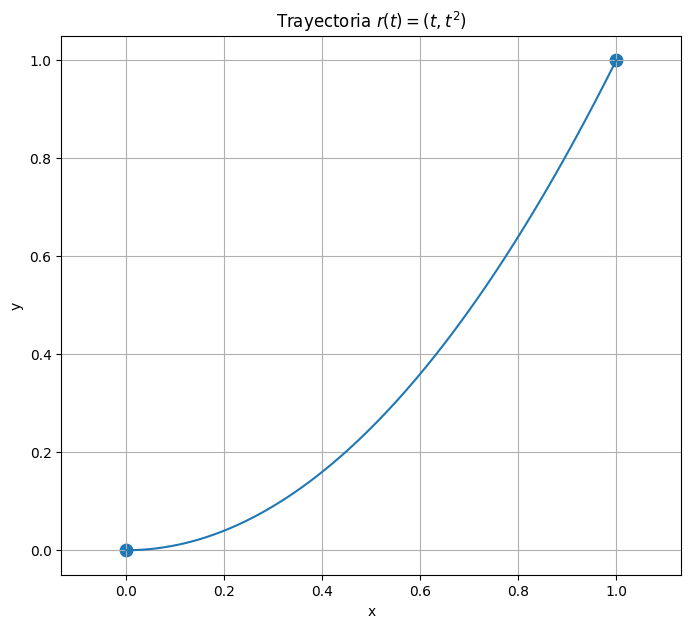

In [8]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1, 200)

x = t
y = t**2

plt.figure(figsize=(8, 7))

plt.plot(x, y)

plt.scatter(
    [x[0], x[-1]],
    [y[0], y[-1]],
    s=80
)

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Trayectoria $r(t)=(t,t^2)$")

plt.axis("equal")
plt.grid()

plt.show()

# 25. Integrales de superficie

Ahora tenemos una superficie:

$$
S.
$$

Para un campo escalar:

$$
\boxed{
\iint_S f\,dS
}
$$

puede representar, por ejemplo, masa de una superficie.

Para un campo vectorial:

$$
\boxed{
\iint_S
\mathbf F\cdot\mathbf n\,dS
}
$$

tenemos el **flujo**.

# 26. ¿Qué significa flujo?

Imagina:

$$
\mathbf F
=
\text{velocidad de un fluido}.
$$

Una superficie actúa como una ventana.

Entonces:

$$
\mathbf F\cdot\mathbf n
$$

mide cuánto del campo atraviesa perpendicularmente la superficie.

Por tanto:

$$
\boxed{
\iint_S
\mathbf F\cdot\mathbf n\,dS
=
\text{flujo}
}
$$

# 27. Ejemplo: flujo a través de una esfera

Consideremos:

$$
\mathbf F(x,y,z)
=
(x,y,z).
$$

La superficie es:

$$
x^2+y^2+z^2=R^2.
$$

La normal exterior es:

$$
\mathbf n
=
\frac{1}{R}(x,y,z).
$$

Entonces:

$$
\mathbf F\cdot\mathbf n
=
\frac{x^2+y^2+z^2}{R}
=
R.
$$

Por tanto:

$$
\iint_S
\mathbf F\cdot\mathbf n\,dS
=
R\operatorname{Area}(S).
$$

Como:

$$
\operatorname{Area}(S)=4\pi R^2,
$$

obtenemos:

$$
\boxed{
4\pi R^3
}
$$

Pero hay una forma mucho más elegante de hacerlo.

Y ahí aparece Gauss.

# 28. Teorema de Gauss

También llamado **teorema de la divergencia**.

Dice:

$$
\boxed{
\iiint_V
\nabla\cdot\mathbf F
\,dV
=
\iint_{\partial V}
\mathbf F\cdot\mathbf n
\,dS
}
$$

En palabras:

> El flujo total que sale de una región cerrada es igual a la integral de la divergencia dentro de esa región.

# 29. Aplicamos Gauss al ejemplo anterior

Tenemos:

$$
\mathbf F=(x,y,z).
$$

Su divergencia:

$$
\nabla\cdot\mathbf F
=
1+1+1
=
3.
$$

Entonces:

$$
\iiint_V3\,dV
=
3\operatorname{Vol}(V).
$$

Para una esfera:

$$
\operatorname{Vol}(V)
=
\frac43\pi R^3.
$$

Así:

$$
3\frac43\pi R^3
=
\boxed{4\pi R^3}.
$$

Mismo resultado.

Pero Gauss evitó calcular directamente la integral de superficie.

# 30. Visualizar Gauss en Python

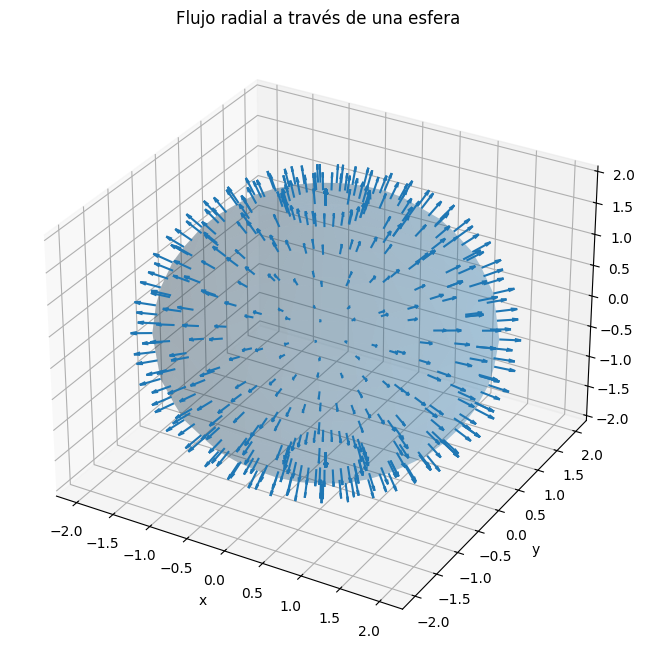

In [9]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2*np.pi, 30)
phi = np.linspace(0, np.pi, 15)

Theta, Phi = np.meshgrid(theta, phi)

R = 2

X = R*np.sin(Phi)*np.cos(Theta)
Y = R*np.sin(Phi)*np.sin(Theta)
Z = R*np.cos(Phi)

# Campo F = (x,y,z)
U = X
V = Y
W = Z

# Normal unitaria
Nx = X/R
Ny = Y/R
Nz = Z/R

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X, Y, Z,
    alpha=0.2
)

ax.quiver(
    X, Y, Z,
    Nx, Ny, Nz,
    length=0.25,
    normalize=True
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Flujo radial a través de una esfera")

plt.show()

La idea geométrica:

```text
              ↑
          ↗       ↖
       ↗             ↖
     →       esfera     ←
       ↘             ↙
          ↘       ↙
              ↓
```

El campo sale de la esfera.


# 31. Teorema de Green

Green es esencialmente el equivalente 2D de estas ideas.

Para:

$$
\mathbf F=(P,Q)
$$

y una región $(D)$ con frontera $(C)$:

$$
\boxed{
\oint_C
P\,dx+Q\,dy
=
\iint_D
\left(
\frac{\partial Q}{\partial x}
-
\frac{\partial P}{\partial y}
\right)dA
}
$$

# 32. ¿Qué está diciendo Green?

El lado izquierdo:

$$
\oint_C\mathbf F\cdot d\mathbf r
$$

mide circulación alrededor de la frontera.

El lado derecho mide la suma de la rotación interna.

Por eso:

$$
\boxed{
\text{circulación en el borde}
=
\text{rotación acumulada en el interior}
}
$$

# 33. Ejemplo difícil de Green

Sea:

$$
\mathbf F=
(-y^3,x^3).
$$

Entonces:

$$
P=-y^3
$$

$$
Q=x^3.
$$

Tenemos:

$$
\frac{\partial Q}{\partial x}=3x^2
$$

y

$$
\frac{\partial P}{\partial y}=-3y^2.
$$

Por tanto:

$$
\frac{\partial Q}{\partial x}
-
\frac{\partial P}{\partial y}
=
3x^2+3y^2.
$$

Así:

$$
\oint_C
-y^3dx+x^3dy
=
\iint_D
3(x^2+y^2)dA.
$$

Si $(D)$ es un círculo:

$$
x^2+y^2\leq R^2,
$$

usamos polares:

$$
=
3
\int_0^{2\pi}
\int_0^R
r^2r\,dr\,d\theta.
$$

Es decir:

$$
3
\int_0^{2\pi}
\int_0^R
r^3dr\,d\theta.
$$

Resultado:

$$
\boxed{
\frac{3\pi R^4}{2}
}
$$

Green convirtió una integral de línea en una integral doble.

# 34. Teorema de Stokes

Stokes generaliza la idea de Green a 3D.

$$
\boxed{
\oint_{\partial S}
\mathbf F\cdot d\mathbf r
=
\iint_S
(\nabla\times\mathbf F)
\cdot\mathbf n
\,dS
}
$$

En palabras:

> La circulación alrededor del borde de una superficie es igual al flujo del curl a través de la superficie.

# 35. Green vs Stokes

Esta comparación debes conocerla perfectamente:

### Green

$$
\boxed{
\text{circulación alrededor de una región 2D}
=
\text{curl acumulado en el interior}
}
$$

### Stokes

$$
\boxed{
\text{circulación alrededor de una curva}
=
\text{curl atravesando una superficie}
}
$$

Green puede verse como un caso especial de Stokes.

# 36. Ejemplo de Stokes

Consideremos:

$$
\mathbf F=(-y,x,0).
$$

Ya sabemos:

$$
\nabla\times\mathbf F=(0,0,2).
$$

Tomemos $(S)$ como el disco:

$$
x^2+y^2\leq R^2
$$

en el plano $(z=0)$.

La normal es:

$$
\mathbf n=(0,0,1).
$$

Entonces:

$$
(\nabla\times\mathbf F)\cdot\mathbf n
=
2.
$$

Por Stokes:

$$
\oint_C
\mathbf F\cdot d\mathbf r
=
\iint_S2\,dS.
$$

Así:

$$
=
2\pi R^2.
$$

Por tanto:

$$
\boxed{
\oint_C
\mathbf F\cdot d\mathbf r
=
2\pi R^2
}
$$

# 37. Visualización de Stokes

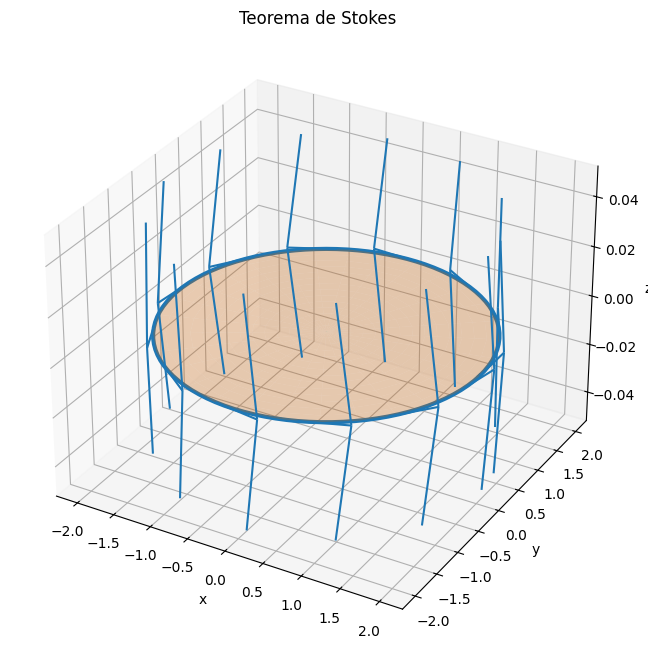

In [10]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2*np.pi, 100)

R = 2

x = R*np.cos(theta)
y = R*np.sin(theta)
z = np.zeros_like(theta)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Curva frontera
ax.plot(x, y, z, linewidth=3)

# Puntos de la superficie
r = np.linspace(0, R, 15)
th = np.linspace(0, 2*np.pi, 30)

R_grid, TH_grid = np.meshgrid(r, th)

X = R_grid*np.cos(TH_grid)
Y = R_grid*np.sin(TH_grid)
Z = np.zeros_like(X)

ax.plot_surface(
    X, Y, Z,
    alpha=0.3
)

# Vectores del campo sobre la frontera
U = -y
V = x
W = np.zeros_like(x)

ax.quiver(
    x[::8],
    y[::8],
    z[::8],
    U[::8],
    V[::8],
    W[::8],
    length=0.3
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Teorema de Stokes")

plt.show()

# 38. La gran conexión entre todos los teoremas

Esta es probablemente la parte más importante conceptualmente.

Tenemos:

## Green

$$
\boxed{
\oint_C
(Pdx+Qdy)
=
\iint_D
(Q_x-P_y)dA
}
$$

## Stokes

$$
\boxed{
\oint_{\partial S}
\mathbf F\cdot d\mathbf r
=
\iint_S
(\nabla\times\mathbf F)\cdot\mathbf n\,dS
}
$$

## Gauss

$$
\boxed{
\iint_{\partial V}
\mathbf F\cdot\mathbf n\,dS
=
\iiint_V
\nabla\cdot\mathbf F\,dV
}
$$

Todos dicen esencialmente:

$$
\boxed{
\text{información en la frontera}
=
\text{información diferencial acumulada en el interior}
}
$$

# 39. Una tabla que debes memorizar

| Concepto            | Fórmula                  | Interpretación      |
| ------------------- | ------------------------ | ------------------- |
| Gradiente           | $(\nabla f)$             | máximo crecimiento  |
| Divergencia         | $(\nabla\cdot F)$        | fuentes/sumideros   |
| Curl                | $(\nabla\times F)$       | rotación            |
| Integral de línea   | $(\int_C F\cdot dr)$     | trabajo/circulación |
| Integral superficie | $(\iint_S F\cdot n\,dS)$ | flujo               |
| Green               | línea ↔ área             | circulación 2D      |
| Stokes              | línea ↔ superficie       | circulación 3D      |
| Gauss               | superficie ↔ volumen     | flujo               |


# 40. Conexión con fluidos

Supongamos un fluido con velocidad:

$$
\mathbf v(x,y,z,t).
$$

Entonces:

### Velocidad

$$
\mathbf v
$$

### Compresibilidad

$$
\nabla\cdot\mathbf v
$$

### Rotación

$$
\nabla\times\mathbf v
$$

### Flujo a través de una superficie

$$
\iint_S
\mathbf v\cdot\mathbf n\,dS.
$$

Esto ya empieza a parecerse a las ecuaciones de fluidos.

Por ejemplo, para un fluido incomprensible:

$$
\boxed{
\nabla\cdot\mathbf v=0
}
$$

Esta ecuación aparecerá posteriormente en **Navier–Stokes**.

# 41. Conexión con PDEs y SciML

Aquí está el motivo por el que este capítulo es tan importante para ti.

En SciML puedes tener una red neuronal:

$$
u_\theta(x,t).
$$

Quieres que satisfaga una PDE.

Por ejemplo, la ecuación de calor:

$$
\frac{\partial u}{\partial t}
=
\alpha\nabla^2u.
$$

Donde:

$$
\nabla^2u
=
\nabla\cdot(\nabla u).
$$

Es decir:

$$
\boxed{
\text{Laplaciano}
=
\text{divergencia del gradiente}
}
$$

¡Acabas de conectar tres conceptos!

$$
u
\rightarrow
\nabla u
\rightarrow
\nabla\cdot(\nabla u)
$$

que da:

$$
\nabla^2u.
$$

# 42. Esto es exactamente lo que hacen las PINNs

En una Physics-Informed Neural Network tienes una red:

$$
u_\theta(x,t).
$$

Y mediante autodiferenciación calculas:

$$
u_t
$$

$$
u_x
$$

$$
u_{xx}
$$

etc.

Luego defines un residual:

$$
r_\theta
=
u_t-\alpha u_{xx}.
$$

Y entrenas minimizando:

$$
\boxed{
L(\theta)
=
\frac1N
\sum_{i=1}^N
|r_\theta(x_i,t_i)|^2
}
$$

Por eso cálculo vectorial, cálculo multivariable y derivadas parciales son **la base matemática de SciML**.

# 43. Una conexión todavía más profunda

Puedes pensar en los conceptos así:

```text
                 CAMPO ESCALAR
                       │
                       │ ∇
                       ▼
                   GRADIENTE
                       │
                       │ div
                       ▼
                 LAPLACIANO


                 CAMPO VECTORIAL
                       │
              ┌────────┴────────┐
              │                 │
             div               curl
              │                 │
              ▼                 ▼
           fuente            rotación
```

Y luego:

```text
      DERIVADAS LOCALES
             │
             ▼
      ┌──────┴──────┐
      │             │
    Green         Stokes
      │             │
      └──────┬──────┘
             │
           Gauss
             │
             ▼
       INTEGRALES
```

# 44. Resumen final

Si quieres una "chuleta mental" para el examen:

$$
\boxed{
\nabla f
=
\text{dirección de máximo crecimiento}
}
$$

$$
\boxed{
\nabla\cdot F
=
\text{fuentes/sumideros}
}
$$

$$
\boxed{
\nabla\times F
=
\text{rotación local}
}
$$

$$
\boxed{
\int_C F\cdot dr
=
\text{trabajo/circulación}
}
$$

$$
\boxed{
\iint_SF\cdot n\,dS
=
\text{flujo}
}
$$

$$
\boxed{
\text{Green: línea}\leftrightarrow\text{área}
}
$$

$$
\boxed{
\text{Stokes: línea}\leftrightarrow\text{superficie}
}
$$

$$
\boxed{
\text{Gauss: superficie}\leftrightarrow\text{volumen}
}
$$

Y para SciML:

$$
\boxed{
\nabla^2u
=
\nabla\cdot(\nabla u)
}
$$

es una de las relaciones que más te conviene tener automatizada mentalmente.

| **Inicio**         | **atrás 5**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./4_5_Integrales_multiples.ipynb) |